# BB84 Quantum Channels

## Notation

The four BB84 states are $|0\rangle$, $|1\rangle$, $|+\rangle=(|0\rangle+|1\rangle)/\sqrt2$, and $|-\rangle=(|0\rangle-|1\rangle)/\sqrt2$. Alice and Bob choose their bases independently and keep detected rounds with matching bases. For uniform bases and state-independent detection,

$$Q=\frac{Q_Z+Q_X}{2}.$$

Here $Q_Z$ and $Q_X$ are conditional error probabilities. Reported finite-batch estimates fluctuate; they are not exact identities for each run. An erased signal is excluded from this denominator. No error correction or privacy amplification is performed.

A state is represented by a density matrix $\rho$, and a subsystem state is obtained by tracing out the other factors. Quantum channels act as

$$\mathcal N(\rho)=\sum_\mu K_\mu\rho K_\mu^\dagger,\qquad\sum_\mu K_\mu^\dagger K_\mu=I.$$

For a projector $P_j$, measurement probability and conditional state are

$$p_j=\operatorname{Tr}(P_j\rho),\qquad\rho_j=\frac{P_j\rho P_j}{p_j}.$$

Each class section includes theory, direct method calls, a BB84 example, and its circuit. Methods beginning with an underscore are internal interfaces shown for completeness. Normal protocol use should prefer the public methods. All formulas refer to the supplied implementation and the assumptions stated in the relevant section.


In [58]:
import numpy as np
from qutip import basis, ket2dm, qeye
from modules import *

N = 400 # number of BB84 bits for key generation

def fresh(): # loads plus state
    plus = (basis(2, 0) + basis(2, 1)).unit()
    return QuantumRegister().load(plus, name="|+>")

## Amplitude Damping (`AmplitudeDamping`) Channel 

The amplitude damping channel decays the excited state $\ket{1}$ to the ground state $\ket{0}$ with probability $\gamma$.

### Construction

The Kraus operators are given as,

$$K_0=\begin{pmatrix}1&0\\0&\sqrt{1-\gamma}\end{pmatrix},\quad K_1=\begin{pmatrix}0&\sqrt\gamma\\0&0\end{pmatrix}.$$

Writing $\rho=\begin{pmatrix}a&z\\z^*&b\end{pmatrix}$ with $a+b=1$ gives

$$\mathcal N(\rho)=\begin{pmatrix}a+\gamma b&\sqrt{1-\gamma}z\\\sqrt{1-\gamma}z^*&(1-\gamma)b\end{pmatrix}.$$

Thus $Q_Z=\gamma/2$, $Q_X=(1-\sqrt{1-\gamma})/2$ and $Q=(\gamma+1-\sqrt{1-\gamma})/4$.

### Implementation

In [27]:
channel = AmplitudeDamping(gamma=0.2) 

The Kraus operators are given below,

In [42]:
Ks = channel.kraus_operators()
for k, K in enumerate(Ks):
    print(f"K_{k}: {K.full()} \n")

K_0: [[1.        +0.j 0.        +0.j]
 [0.        +0.j 0.89442719+0.j]] 

K_1: [[0.       +0.j 0.4472136+0.j]
 [0.       +0.j 0.       +0.j]] 



It is easy to see they follow the relation,

$$\sum_\mu K_\mu^\dagger K_\mu=I,$$

In [41]:
complete = sum((K.dag() * K for K in Ks), 0 * qeye(Ks[0].dims[1])) # completeness, ideally I
assert (complete - qeye(Ks[0].dims[1])).norm() < 1e-09

Applying this channel to one qubit gives,

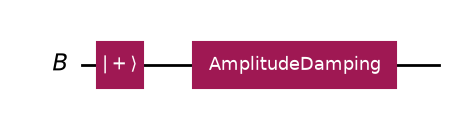

Output dimensions: [2]
Output state: [[0.6      +0.j 0.4472136+0.j]
 [0.4472136+0.j 0.4      +0.j]]


In [53]:
# Channel acting on one qubit
r = fresh()
channel.apply(r, "B")
fig = r.display(dpi=100)
print(f"Output dimensions: {r.dims}")
print(f"Output state: {r.state.full()}")

For two qubits,

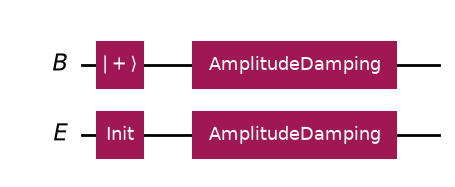

Output dimensions: [2, 2]


In [55]:
r2 = fresh()
r2.add_ancilla("E", basis(2, 1))
channel.apply_each(r2, ["B", "E"])
fig = r2.display(dpi=100)

print("Output dimensions:", r2.dims)

### BB84 circuit

The diagram below is a recorded, detected round with matching bases. The signal wire is labelled B; probe wires appear when present. Eve’s delayed measurement is included for probe attacks. Noise boxes denote the full channel map; their internal Kraus branches are not individual unitary gates.

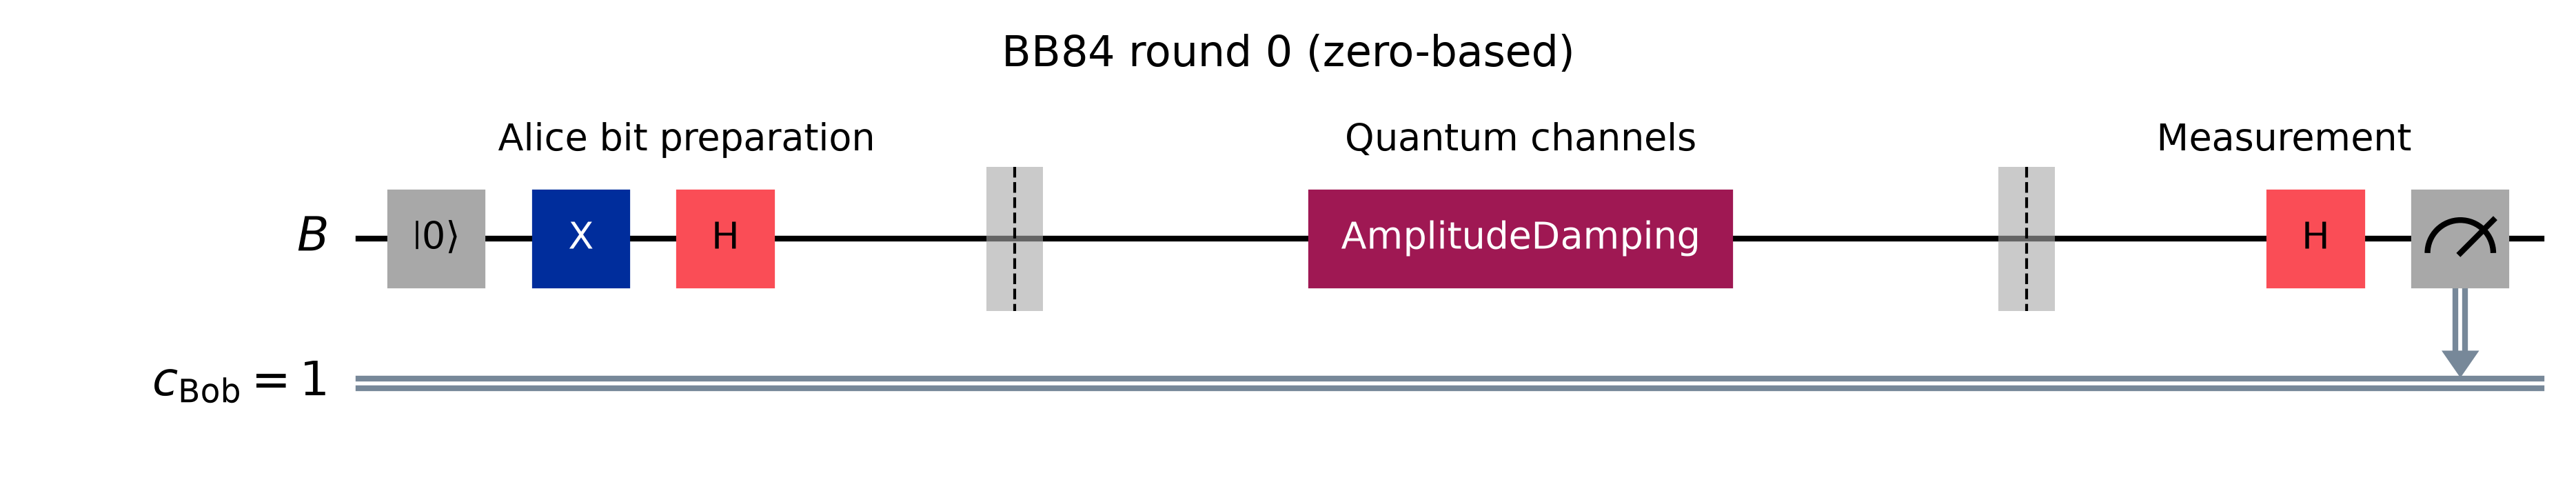

In [3]:
demo_bb = BB84(seed=82, number_bits=24)
demo_bb.key_generation(signal_channel=AmplitudeDamping(0.2), record_rounds=range(24))
idx = int(np.flatnonzero(demo_bb.sifted_mask)[0])
fig = demo_bb.display(round_index=idx, show=False)

print(f"QBER: {demo_bb.qber()}")
print(f"Loss rate: {demo_bb.loss_rate()}") # come back to this ???

## Generalized Amplitude Damping (`GeneralizedAmplitudeDamping`) Channel

The generalized amplitude damping channel $\mathcal{A}_{\gamma, N}$ is a qubit-qubit channel that allows for excitations from lower to higher levels.

### Mathematical construction

$$K_0=\sqrt{1-N}\begin{pmatrix}1&0\\0&\sqrt{1-\gamma}\end{pmatrix},\quad K_1=\sqrt{(1-N)\gamma}|0\rangle\langle1|,$$

$$K_2=\sqrt N\begin{pmatrix}\sqrt{1-\gamma}&0\\0&1\end{pmatrix},\quad K_3=\sqrt{N\gamma}|1\rangle\langle0|.$$

The excited population obeys $b'=(1-\gamma)b+\gamma N$ and $z'=\sqrt{1-\gamma}z$. Thus the fixed point is $b=N$. For equally likely BB84 bits, the average QBER is the same as amplitude damping, although the conditional errors and output bias depend on N.

### Parameters and methods
`__init__` constructs the channel from the parameters below; `kraus_operators` gives exactly the matrices derived above. The next demonstration explicitly calls both, followed by inherited `apply` and `apply_each`. Erasure classes additionally demonstrate `measurement_projectors`; generalized dephasing demonstrates both its ordinary constructor and `from_correlation_matrix`.

In [4]:
channel = GeneralizedAmplitudeDamping(0.2, 0.1)
Ks = channel.kraus_operators()
for k, K in enumerate(Ks):
    print("K", k, K.full())
complete = sum((K.dag() * K for K in Ks), 0 * qeye(Ks[0].dims[1]))
assert (complete - qeye(Ks[0].dims[1])).norm() < 1e-09
r = fresh()
channel.apply(r, "B")
print("output dimensions / state:", r.dims, r.state.full())
r2 = fresh()
r2.add_ancilla("E", basis(2, 1))
channel.apply_each(r2, ["B", "E"])
print("independent outputs:", r2.dims)
bb = BB84(seed=123, number_bits=N)
bb.key_generation(signal_channel=channel)
print("QBER, loss:", bb.qber(), bb.loss_rate())


K 0 [[0.9486833 +0.j 0.        +0.j]
 [0.        +0.j 0.84852814+0.j]]
K 1 [[0.        +0.j 0.42426407+0.j]
 [0.        +0.j 0.        +0.j]]
K 2 [[0.28284271+0.j 0.        +0.j]
 [0.        +0.j 0.31622777+0.j]]
K 3 [[0.        +0.j 0.        +0.j]
 [0.14142136+0.j 0.        +0.j]]
output dimensions / state: [2] [[0.58     +0.j 0.4472136+0.j]
 [0.4472136+0.j 0.42     +0.j]]
independent outputs: [2, 2]
QBER, loss: 0.08530805687203792 0.0


### BB84 circuit

The diagram below is a recorded, detected round with matching bases. The signal wire is labelled B; probe wires appear when present. Eve’s delayed measurement is included for probe attacks. Noise boxes denote the full channel map; their internal Kraus branches are not individual unitary gates.

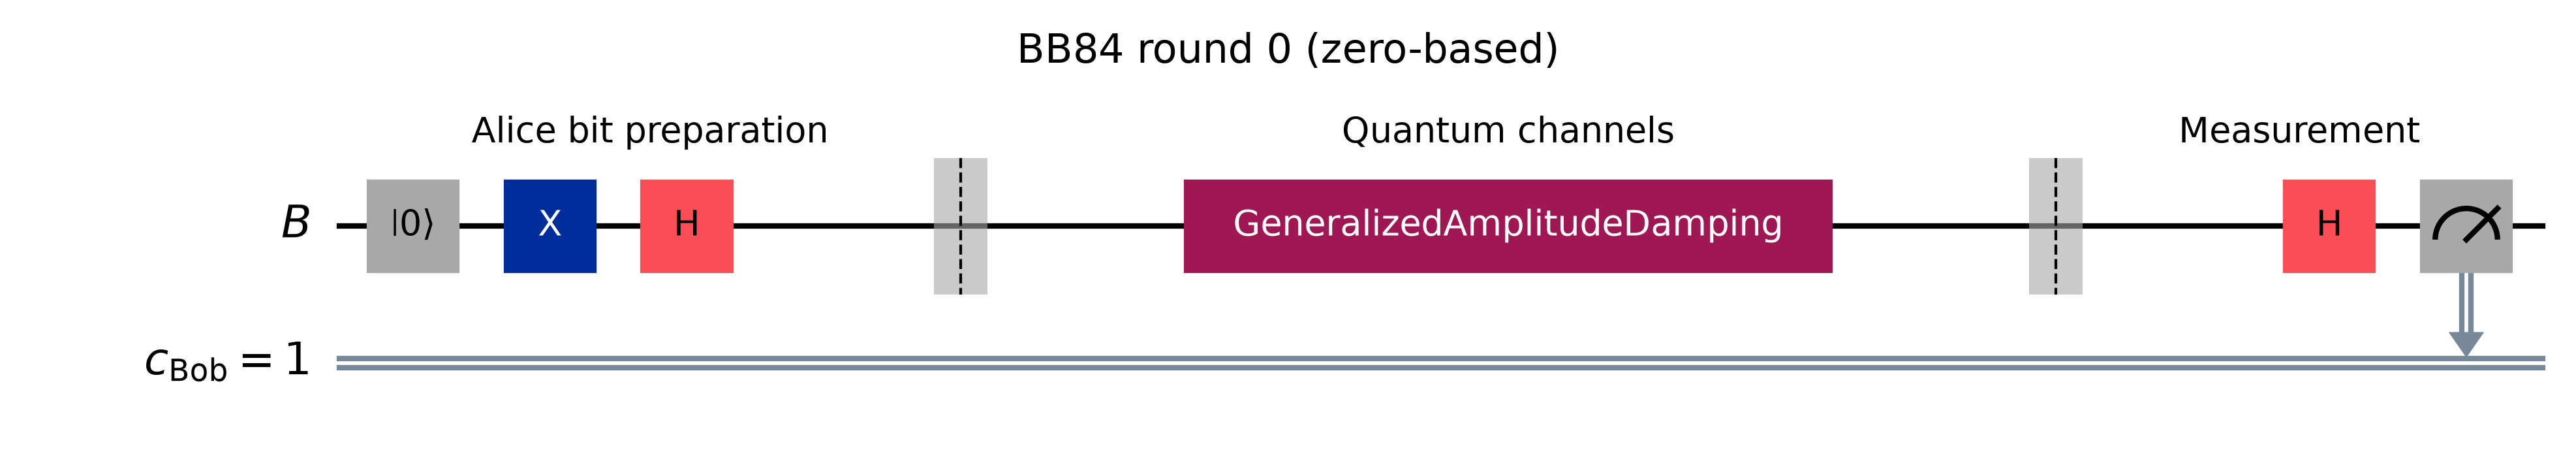

In [5]:
demo_bb = BB84(seed=82, number_bits=24)
demo_bb.key_generation(signal_channel=GeneralizedAmplitudeDamping(0.2, 0.1), record_rounds=range(24))
idx = int(np.flatnonzero(demo_bb.sifted_mask)[0])
fig = demo_bb.display(round_index=idx, show=False)

## BitFlip

The environment is not sampled explicitly: the register stores the weighted sum of the unchanged and flipped branches. The interval is $0\leq p\leq1$. At $p=0$ the map is identity; at $p=1$ it is a deterministic X gate. The output of a pure state may be mixed for intermediate probabilities. Distinguish a flipped computational bit from a flipped BB84 bit: the latter depends on which basis was used.

### Mathematical construction

$$K_0=\sqrt{1-p}I,\quad K_1=\sqrt pX,\quad (r_x,r_y,r_z)\mapsto(r_x,(1-2p)r_y,(1-2p)r_z).$$
Here $\rho=(I+\mathbf r\cdot\boldsymbol\sigma)/2$. A Z measurement sees bit error $p$, whereas an X eigenstate changes only by a physically irrelevant phase under X. Therefore $Q_Z=p$, $Q_X=0$, $Q=p/2$.

### Parameters and methods
`__init__` constructs the channel from the parameters below; `kraus_operators` gives exactly the matrices derived above. The next demonstration explicitly calls both, followed by inherited `apply` and `apply_each`. Erasure classes additionally demonstrate `measurement_projectors`; generalized dephasing demonstrates both its ordinary constructor and `from_correlation_matrix`.

In [6]:
channel = BitFlip(0.2)
Ks = channel.kraus_operators()
for k, K in enumerate(Ks):
    print("K", k, K.full())
complete = sum((K.dag() * K for K in Ks), 0 * qeye(Ks[0].dims[1]))
assert (complete - qeye(Ks[0].dims[1])).norm() < 1e-09
r = fresh()
channel.apply(r, "B")
print("output dimensions / state:", r.dims, r.state.full())
r2 = fresh()
r2.add_ancilla("E", basis(2, 1))
channel.apply_each(r2, ["B", "E"])
print("independent outputs:", r2.dims)
bb = BB84(seed=123, number_bits=N)
bb.key_generation(signal_channel=channel)
print("QBER, loss:", bb.qber(), bb.loss_rate())


K 0 [[0.89442719+0.j 0.        +0.j]
 [0.        +0.j 0.89442719+0.j]]
K 1 [[0.       +0.j 0.4472136+0.j]
 [0.4472136+0.j 0.       +0.j]]
output dimensions / state: [2] [[0.5+0.j 0.5+0.j]
 [0.5+0.j 0.5+0.j]]
independent outputs: [2, 2]
QBER, loss: 0.09004739336492891 0.0


### BB84 circuit

The diagram below is a recorded, detected round with matching bases. The signal wire is labelled B; probe wires appear when present. Eve’s delayed measurement is included for probe attacks. Noise boxes denote the full channel map; their internal Kraus branches are not individual unitary gates.

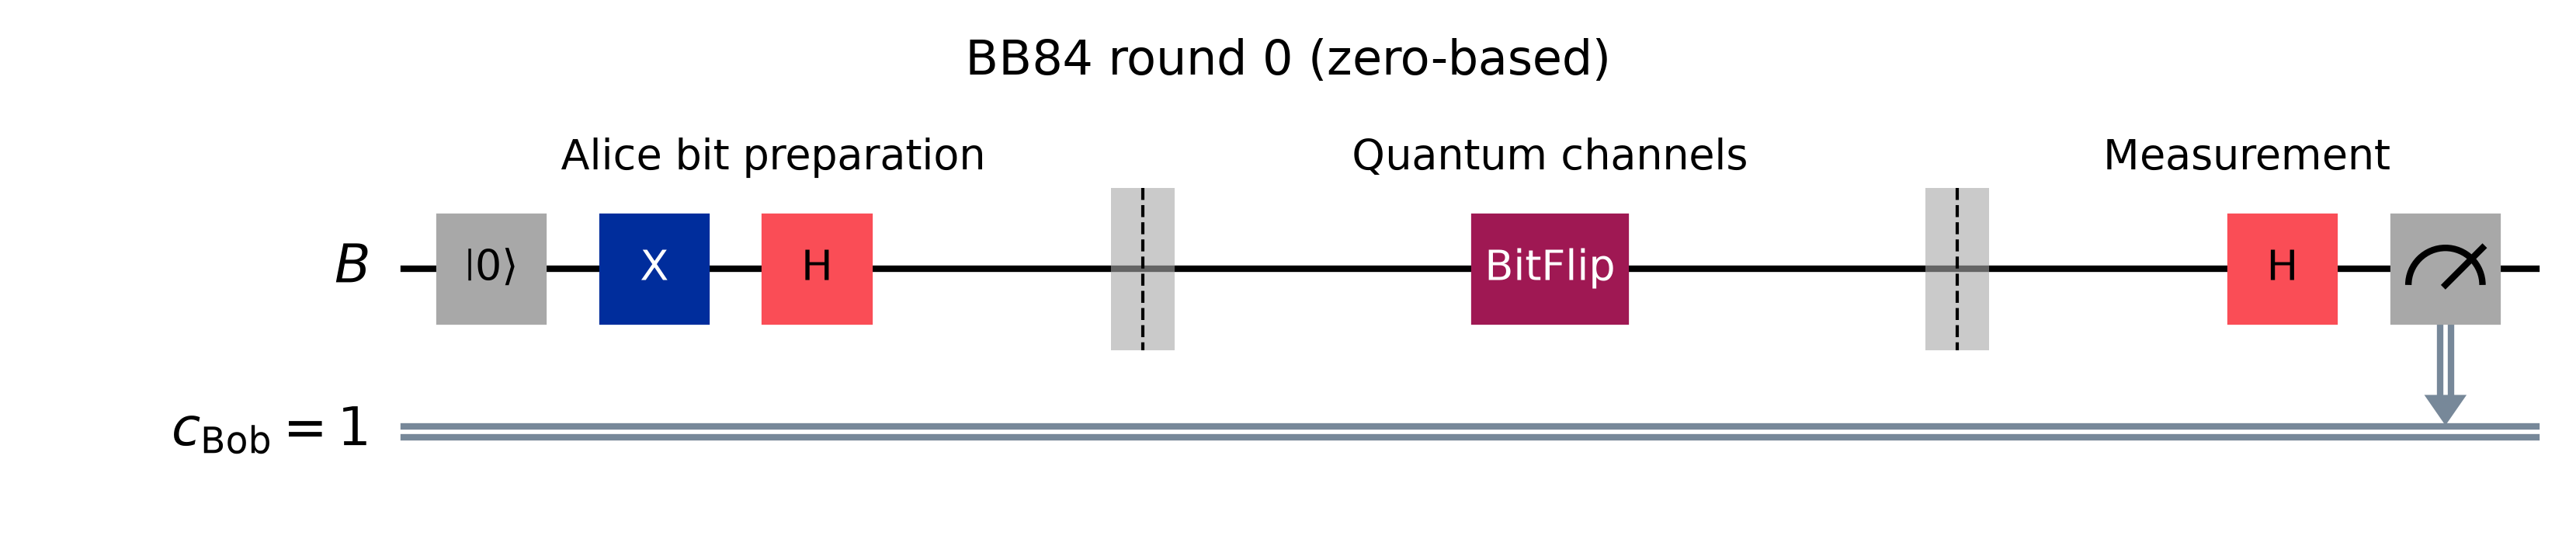

In [7]:
demo_bb = BB84(seed=82, number_bits=24)
demo_bb.key_generation(signal_channel=BitFlip(0.2), record_rounds=range(24))
idx = int(np.flatnonzero(demo_bb.sifted_mask)[0])
fig = demo_bb.display(round_index=idx, show=False)
display(fig)


## PhaseFlip

A relative phase is observable when the state is later measured in a complementary basis. This is why phase noise leaves computational populations alone but produces errors in the X key. The interval is $0\leq p\leq1$. A loss of coherence and a deterministic phase inversion are physically different; the coherence factor changes sign beyond the midpoint. The channel does not erase a photon and therefore cannot produce the erasure flag.

### Mathematical construction

$$K_0=\sqrt{1-p}I,\quad K_1=\sqrt pZ,\quad (r_x,r_y,r_z)\mapsto((1-2p)r_x,(1-2p)r_y,r_z).$$
The off-diagonal entry becomes $(1-2p)\rho_{01}$. At $p=1/2$ all Z-basis coherence vanishes; at $p=1$ the map is the deterministic unitary Z, not complete dephasing. $Q_Z=0$, $Q_X=p$, $Q=p/2$.

### Parameters and methods
`__init__` constructs the channel from the parameters below; `kraus_operators` gives exactly the matrices derived above. The next demonstration explicitly calls both, followed by inherited `apply` and `apply_each`. Erasure classes additionally demonstrate `measurement_projectors`; generalized dephasing demonstrates both its ordinary constructor and `from_correlation_matrix`.

In [8]:
channel = PhaseFlip(0.2)
Ks = channel.kraus_operators()
for k, K in enumerate(Ks):
    print("K", k, K.full())
complete = sum((K.dag() * K for K in Ks), 0 * qeye(Ks[0].dims[1]))
assert (complete - qeye(Ks[0].dims[1])).norm() < 1e-09
r = fresh()
channel.apply(r, "B")
print("output dimensions / state:", r.dims, r.state.full())
r2 = fresh()
r2.add_ancilla("E", basis(2, 1))
channel.apply_each(r2, ["B", "E"])
print("independent outputs:", r2.dims)
bb = BB84(seed=123, number_bits=N)
bb.key_generation(signal_channel=channel)
print("QBER, loss:", bb.qber(), bb.loss_rate())


K 0 [[0.89442719+0.j 0.        +0.j]
 [0.        +0.j 0.89442719+0.j]]
K 1 [[ 0.4472136+0.j  0.       +0.j]
 [ 0.       +0.j -0.4472136+0.j]]
output dimensions / state: [2] [[0.5+0.j 0.3+0.j]
 [0.3+0.j 0.5+0.j]]
independent outputs: [2, 2]
QBER, loss: 0.10900473933649289 0.0


### BB84 circuit

The diagram below is a recorded, detected round with matching bases. The signal wire is labelled B; probe wires appear when present. Eve’s delayed measurement is included for probe attacks. Noise boxes denote the full channel map; their internal Kraus branches are not individual unitary gates.

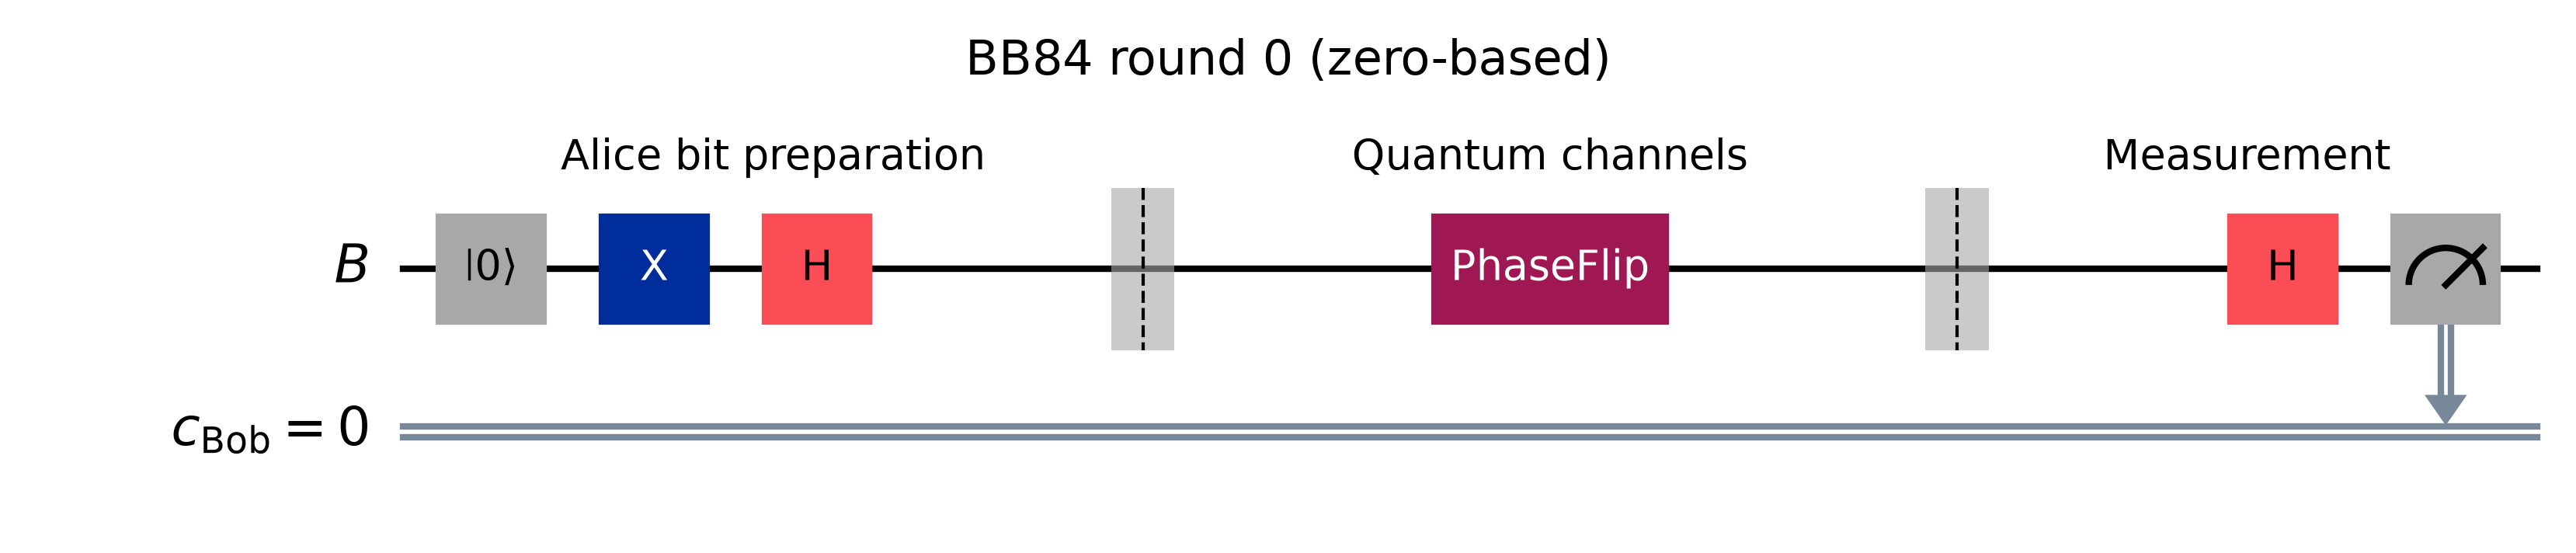

In [9]:
demo_bb = BB84(seed=82, number_bits=24)
demo_bb.key_generation(signal_channel=PhaseFlip(0.2), record_rounds=range(24))
idx = int(np.flatnonzero(demo_bb.sifted_mask)[0])
fig = demo_bb.display(round_index=idx, show=False)
display(fig)


## Pauli

All four probabilities must lie in $[0,1]$. The identity probability is supplied explicitly rather than inferred by subtraction. Different distributions can yield the same average QBER while producing different errors in the individual bases. This makes separate basis errors useful when comparing channels. Each Kraus operator is a unitary Pauli multiplied by the square root of its probability; the square root is required because the channel contains an operator on both sides of the density matrix.

### Mathematical construction

$$K_0=\sqrt{p_1}I,\quad K_1=\sqrt{p_2}X,\quad K_2=\sqrt{p_3}Y,\quad K_3=\sqrt{p_4}Z,\quad\sum_i p_i=1.$$
$$\mathcal N(\rho)=p_1\rho+p_2X\rho X+p_3Y\rho Y+p_4Z\rho Z.$$
X and Y anticommute with Z, while Y and Z anticommute with X. Consequently
$$Q_Z=p_2+p_3,\qquad Q_X=p_3+p_4,\qquad Q=\frac{p_2+2p_3+p_4}{2}.$$
The constructor tolerates tiny summation roundoff and normalizes the accepted probabilities.

### Parameters and methods
`__init__` constructs the channel from the parameters below; `kraus_operators` gives exactly the matrices derived above. The next demonstration explicitly calls both, followed by inherited `apply` and `apply_each`. Erasure classes additionally demonstrate `measurement_projectors`; generalized dephasing demonstrates both its ordinary constructor and `from_correlation_matrix`.

In [10]:
channel = Pauli(0.7, 0.1, 0.1, 0.1)
Ks = channel.kraus_operators()
for k, K in enumerate(Ks):
    print("K", k, K.full())
complete = sum((K.dag() * K for K in Ks), 0 * qeye(Ks[0].dims[1]))
assert (complete - qeye(Ks[0].dims[1])).norm() < 1e-09
r = fresh()
channel.apply(r, "B")
print("output dimensions / state:", r.dims, r.state.full())
r2 = fresh()
r2.add_ancilla("E", basis(2, 1))
channel.apply_each(r2, ["B", "E"])
print("independent outputs:", r2.dims)
bb = BB84(seed=123, number_bits=N)
bb.key_generation(signal_channel=channel)
print("QBER, loss:", bb.qber(), bb.loss_rate())


K 0 [[0.83666003+0.j 0.        +0.j]
 [0.        +0.j 0.83666003+0.j]]
K 1 [[0.        +0.j 0.31622777+0.j]
 [0.31622777+0.j 0.        +0.j]]
K 2 [[0.+0.j         0.-0.31622777j]
 [0.+0.31622777j 0.+0.j        ]]
K 3 [[ 0.31622777+0.j  0.        +0.j]
 [ 0.        +0.j -0.31622777+0.j]]
output dimensions / state: [2] [[0.5+0.j 0.3+0.j]
 [0.3+0.j 0.5+0.j]]
independent outputs: [2, 2]
QBER, loss: 0.1990521327014218 0.0


### BB84 circuit

The diagram below is a recorded, detected round with matching bases. The signal wire is labelled B; probe wires appear when present. Eve’s delayed measurement is included for probe attacks. Noise boxes denote the full channel map; their internal Kraus branches are not individual unitary gates.

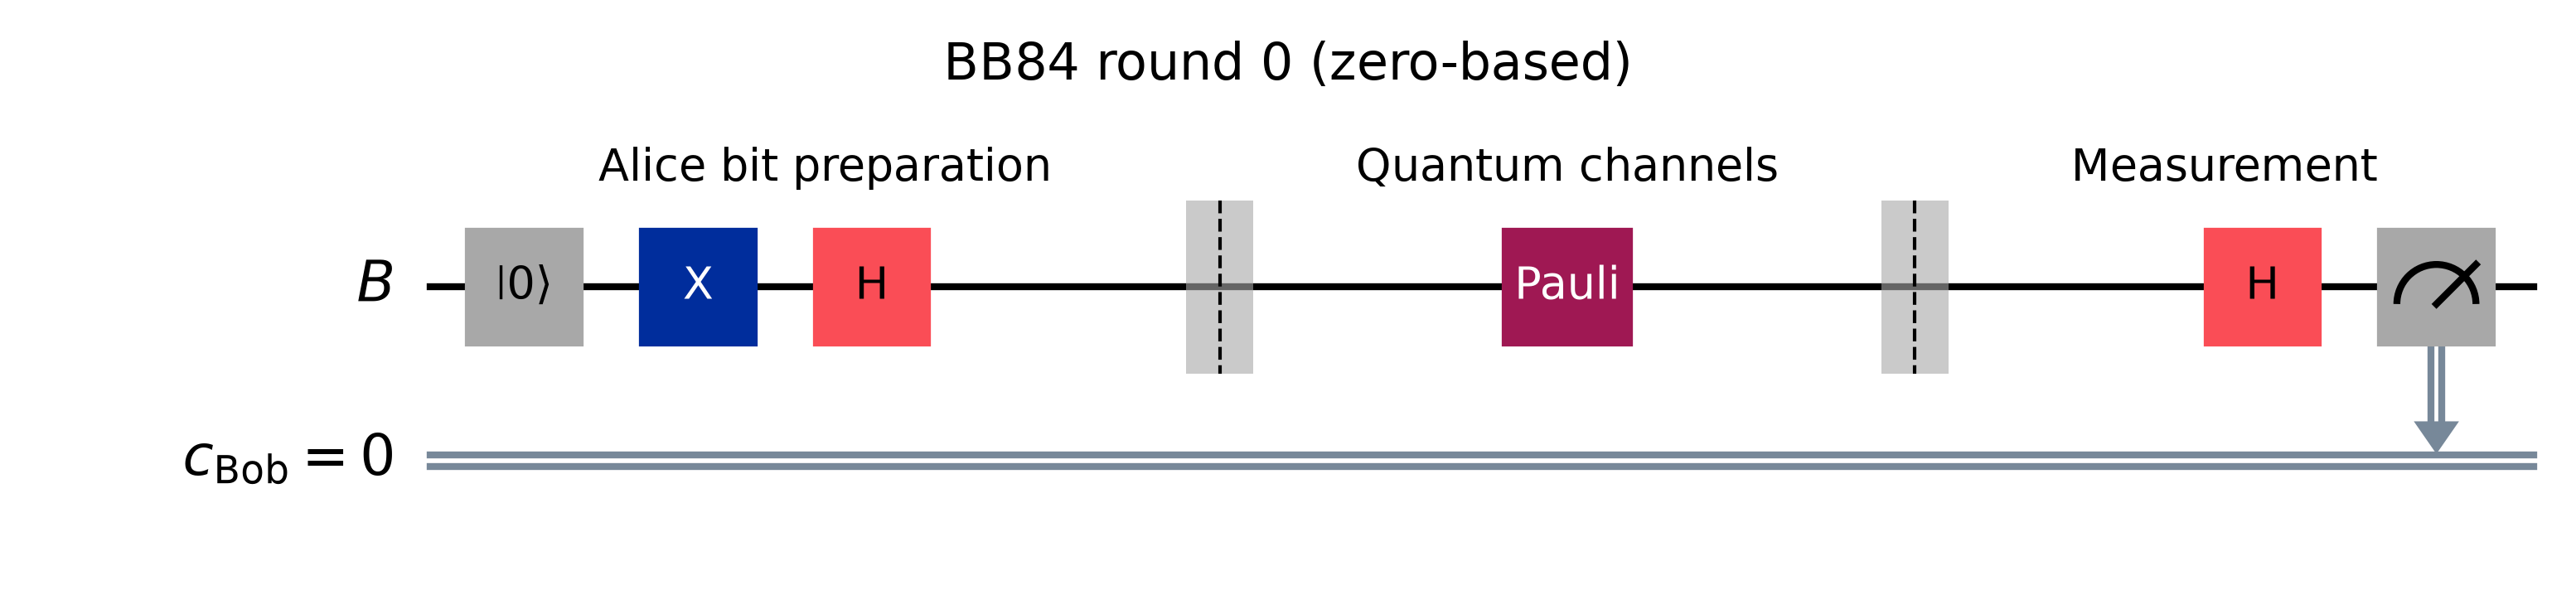

In [11]:
demo_bb = BB84(seed=82, number_bits=24)
demo_bb.key_generation(
    signal_channel=Pauli(0.7, 0.1, 0.1, 0.1), record_rounds=range(24)
)
idx = int(np.flatnonzero(demo_bb.sifted_mask)[0])
fig = demo_bb.display(round_index=idx, show=False)
display(fig)


## Depolarizing

This implementation parameterizes the total probability of a nonidentity Pauli error. It is therefore important not to identify its parameter with the mixing weight of the maximally mixed state. The allowed interval is $0\leq p\leq1$. Even where the alternative identity-plus-mixing expression has a negative identity coefficient, the original nonnegative Kraus probabilities prove that the channel is valid. The two BB84 bases are affected equally because the three Pauli errors are weighted equally.

### Mathematical construction

$$K_0=\sqrt{1-p}I,\quad (K_1,K_2,K_3)=\sqrt{p/3}(X,Y,Z).$$
Using $X\rho X+Y\rho Y+Z\rho Z=2I-\rho$ for normalized qubit states,
$$\mathcal N(\rho)=(1-4p/3)\rho+(4p/3)I/2.$$
Hence $\mathbf r'=(1-4p/3)\mathbf r$, $Q_Z=Q_X=2p/3$. At $p=3/4$ the output is $I/2$; at $p=1$ the Bloch vector is reversed and shrunk by 1/3.

### Parameters and methods
`__init__` constructs the channel from the parameters below; `kraus_operators` gives exactly the matrices derived above. The next demonstration explicitly calls both, followed by inherited `apply` and `apply_each`. Erasure classes additionally demonstrate `measurement_projectors`; generalized dephasing demonstrates both its ordinary constructor and `from_correlation_matrix`.

In [12]:
channel = Depolarizing(0.15)
Ks = channel.kraus_operators()
for k, K in enumerate(Ks):
    print("K", k, K.full())
complete = sum((K.dag() * K for K in Ks), 0 * qeye(Ks[0].dims[1]))
assert (complete - qeye(Ks[0].dims[1])).norm() < 1e-09
r = fresh()
channel.apply(r, "B")
print("output dimensions / state:", r.dims, r.state.full())
r2 = fresh()
r2.add_ancilla("E", basis(2, 1))
channel.apply_each(r2, ["B", "E"])
print("independent outputs:", r2.dims)
bb = BB84(seed=123, number_bits=N)
bb.key_generation(signal_channel=channel)
print("QBER, loss:", bb.qber(), bb.loss_rate())


K 0 [[0.92195445+0.j 0.        +0.j]
 [0.        +0.j 0.92195445+0.j]]
K 1 [[0.       +0.j 0.2236068+0.j]
 [0.2236068+0.j 0.       +0.j]]
K 2 [[0.+0.j        0.-0.2236068j]
 [0.+0.2236068j 0.+0.j       ]]
K 3 [[ 0.2236068+0.j  0.       +0.j]
 [ 0.       +0.j -0.2236068+0.j]]
output dimensions / state: [2] [[0.5+0.j 0.4+0.j]
 [0.4+0.j 0.5+0.j]]
independent outputs: [2, 2]
QBER, loss: 0.0995260663507109 0.0


### BB84 circuit

The diagram below is a recorded, detected round with matching bases. The signal wire is labelled B; probe wires appear when present. Eve’s delayed measurement is included for probe attacks. Noise boxes denote the full channel map; their internal Kraus branches are not individual unitary gates.

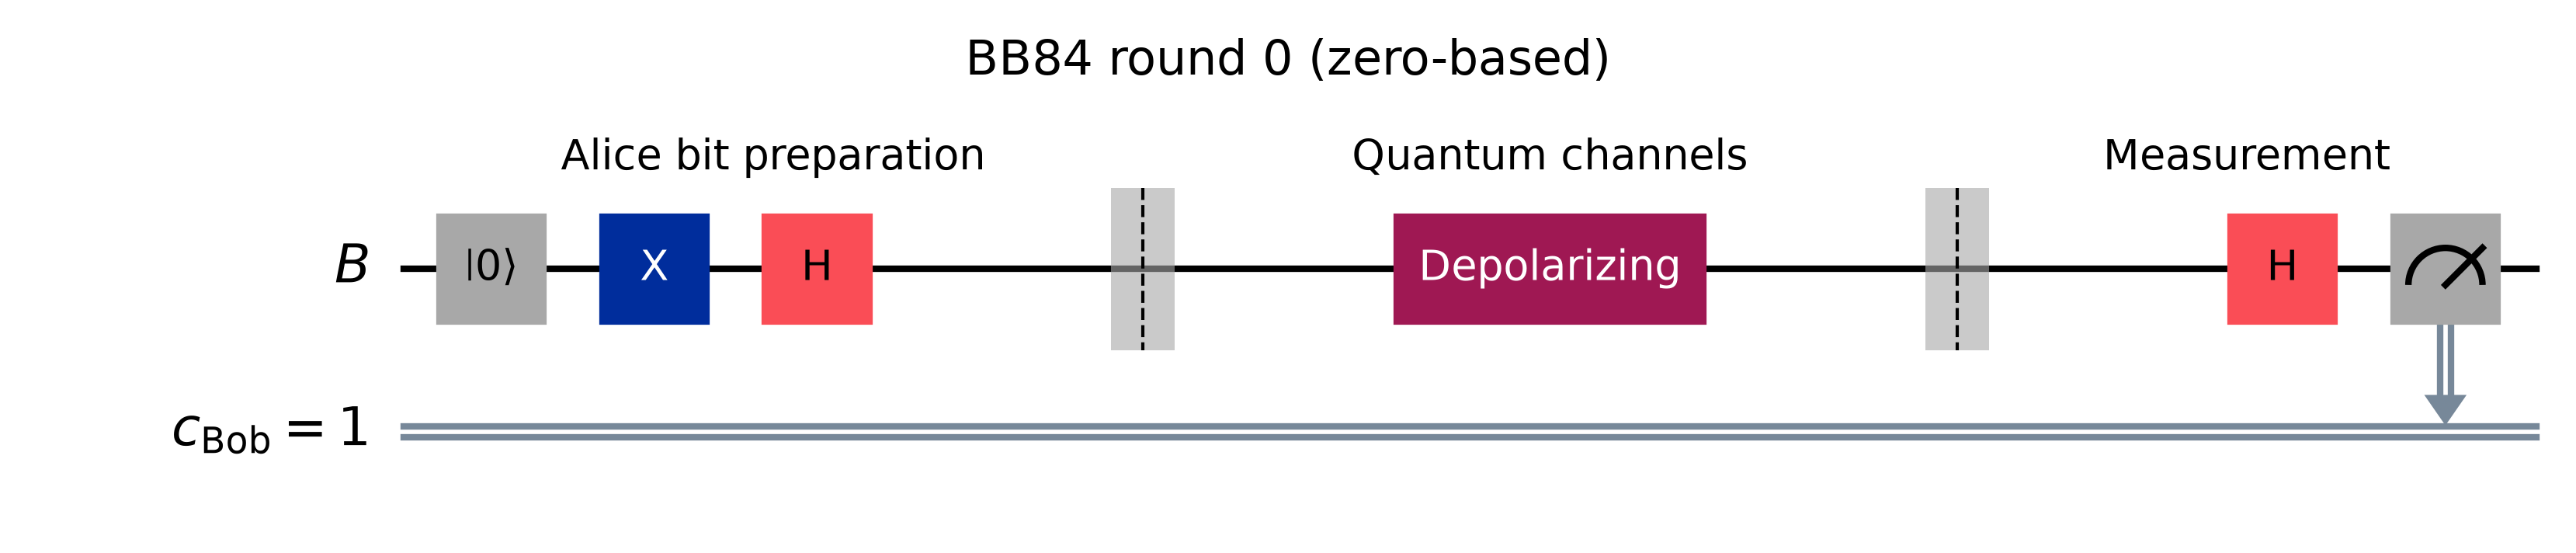

In [13]:
demo_bb = BB84(seed=82, number_bits=24)
demo_bb.key_generation(signal_channel=Depolarizing(0.15), record_rounds=range(24))
idx = int(np.flatnonzero(demo_bb.sifted_mask)[0])
fig = demo_bb.display(round_index=idx, show=False)
display(fig)


## DampingDephasing

The population and coherence formulas provide a useful way to separate the two physical effects: only damping transfers population, while both mechanisms reduce coherence. The constructor allows $0\leq g\leq1$ and $0\leq p\leq1/2$. In this range the coherence factor is nonnegative. At full damping the output is the ground state regardless of the phase-noise parameter. The three-operator representation combines redundant decay branches that would appear when composing two separate channel descriptions.

### Mathematical construction

$$K_0=\sqrt{1-p}\operatorname{diag}(1,\sqrt{1-g}),\quad K_1=\sqrt g|0\rangle\langle1|,\quad K_2=\sqrt p\operatorname{diag}(1,-\sqrt{1-g}).$$
Their squared products sum to I. The output entries satisfy $b'=(1-g)b$ and $z'=(1-2p)\sqrt{1-g}z$. Therefore
$$Q_Z=g/2,\quad Q_X=\frac{1-(1-2p)\sqrt{1-g}}2,\quad Q=\frac{g+1-(1-2p)\sqrt{1-g}}4.$$
Setting $g=0$ gives phase flip; setting $p=0$ gives amplitude damping.

### Parameters and methods
`__init__` constructs the channel from the parameters below; `kraus_operators` gives exactly the matrices derived above. The next demonstration explicitly calls both, followed by inherited `apply` and `apply_each`. Erasure classes additionally demonstrate `measurement_projectors`; generalized dephasing demonstrates both its ordinary constructor and `from_correlation_matrix`.

In [14]:
channel = DampingDephasing(p=0.1, g=0.2)
Ks = channel.kraus_operators()
for k, K in enumerate(Ks):
    print("K", k, K.full())
complete = sum((K.dag() * K for K in Ks), 0 * qeye(Ks[0].dims[1]))
assert (complete - qeye(Ks[0].dims[1])).norm() < 1e-09
r = fresh()
channel.apply(r, "B")
print("output dimensions / state:", r.dims, r.state.full())
r2 = fresh()
r2.add_ancilla("E", basis(2, 1))
channel.apply_each(r2, ["B", "E"])
print("independent outputs:", r2.dims)
bb = BB84(seed=123, number_bits=N)
bb.key_generation(signal_channel=channel)
print("QBER, loss:", bb.qber(), bb.loss_rate())


K 0 [[0.9486833 +0.j 0.        +0.j]
 [0.        +0.j 0.84852814+0.j]]
K 1 [[0.       +0.j 0.4472136+0.j]
 [0.       +0.j 0.       +0.j]]
K 2 [[ 0.31622777+0.j  0.        +0.j]
 [ 0.        +0.j -0.28284271+0.j]]
output dimensions / state: [2] [[0.6       +0.j 0.35777088+0.j]
 [0.35777088+0.j 0.4       +0.j]]
independent outputs: [2, 2]
QBER, loss: 0.13744075829383887 0.0


### BB84 circuit

The diagram below is a recorded, detected round with matching bases. The signal wire is labelled B; probe wires appear when present. Eve’s delayed measurement is included for probe attacks. Noise boxes denote the full channel map; their internal Kraus branches are not individual unitary gates.

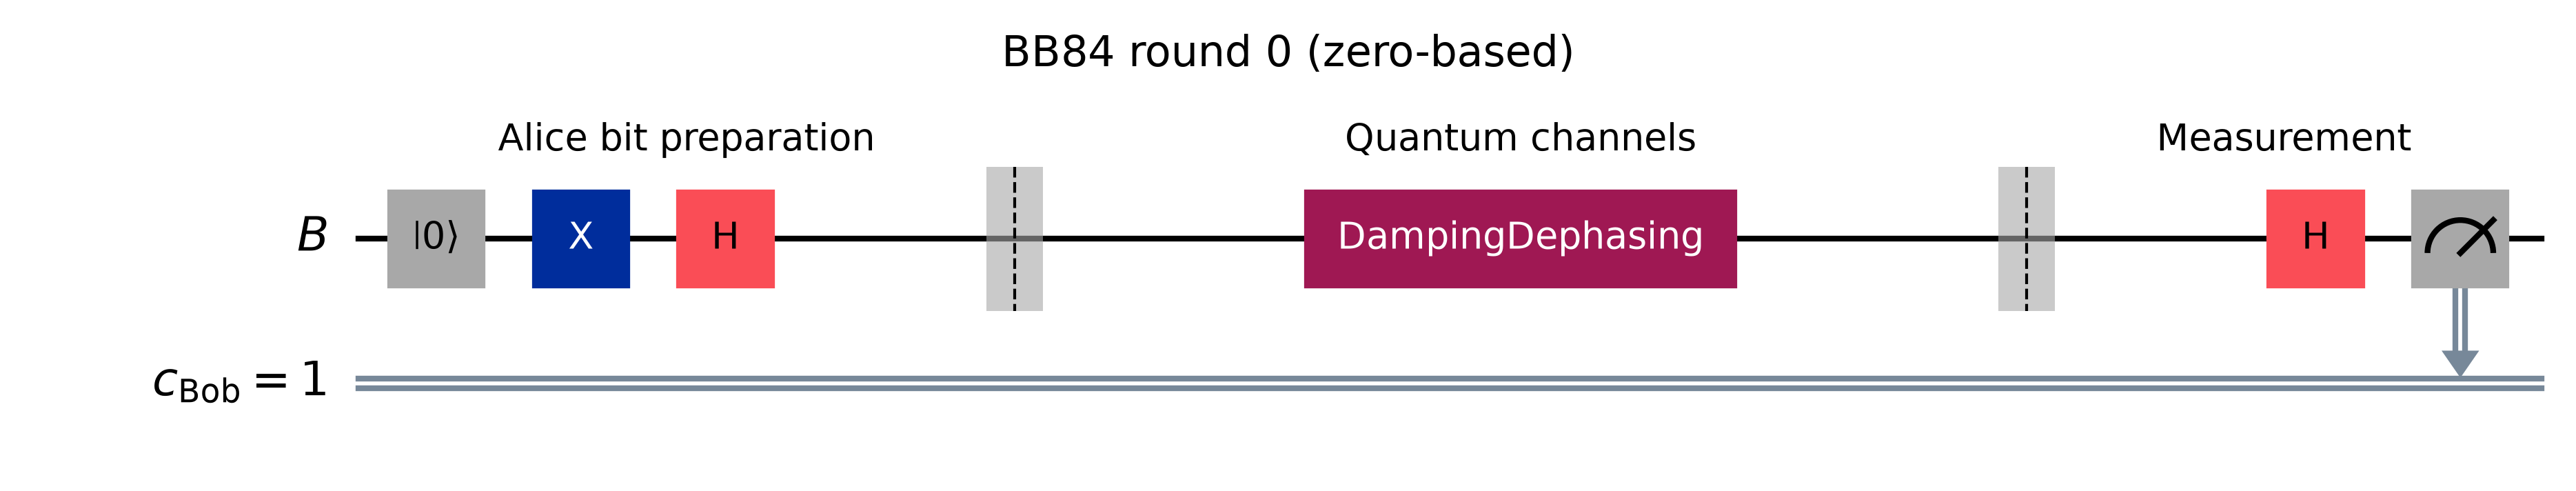

In [15]:
demo_bb = BB84(seed=82, number_bits=24)
demo_bb.key_generation(
    signal_channel=DampingDephasing(p=0.1, g=0.2), record_rounds=range(24)
)
idx = int(np.flatnonzero(demo_bb.sifted_mask)[0])
fig = demo_bb.display(round_index=idx, show=False)
display(fig)


## GeneralizedDephasing

Diagonal populations remain unchanged in the selected basis because the diagonal entries of the correlation matrix are unity. Off-diagonal entries record how distinguishable the environment states are: identical environment states preserve coherence, while orthogonal ones destroy it. Complex overlaps can introduce phase shifts as well as attenuation. Although the class supports more than two levels, the BB84 signal examples use two-dimensional inputs. A different preserved basis must be given as a complete orthonormal set of QuTiP kets.

### Mathematical construction

An environment interaction $|i\rangle\mapsto|i\rangle|\phi_i\rangle$ gives, after tracing the environment,
$$\mathcal N(\rho)_{ij}=\rho_{ij}\langle\phi_j|\phi_i\rangle=C_{ij}\rho_{ij}.$$
If $a_{\mu i}=\langle\mu|\phi_i\rangle$, the Kraus operators are
$$K_\mu=B\operatorname{diag}(a_{\mu0},\ldots,a_{\mu,d-1})B^\dagger,$$
where columns of B specify the preserved basis. Normalized environment states imply $\sum_\mu K_\mu^\dagger K_\mu=I$. The matrix constructor factors $C=AA^\dagger$ and uses rows of A as environment amplitudes. It requires $C=C^\dagger$, $C\succeq0$, and $C_{ii}=1$. For $C_{01}=c$ in the Z basis, $Q_Z=0$, $Q_X=(1-\operatorname{Re}c)/2$.

### Parameters and methods
`__init__` constructs the channel from the parameters below; `kraus_operators` gives exactly the matrices derived above. The next demonstration explicitly calls both, followed by inherited `apply` and `apply_each`. Erasure classes additionally demonstrate `measurement_projectors`; generalized dephasing demonstrates both its ordinary constructor and `from_correlation_matrix`.

In [16]:
channel = GeneralizedDephasing.from_correlation_matrix([[1, 0.6], [0.6, 1]])
Ks = channel.kraus_operators()
for k, K in enumerate(Ks):
    print("K", k, K.full())
complete = sum((K.dag() * K for K in Ks), 0 * qeye(Ks[0].dims[1]))
assert (complete - qeye(Ks[0].dims[1])).norm() < 1e-09
r = fresh()
channel.apply(r, "B")
print("output dimensions / state:", r.dims, r.state.full())
r2 = fresh()
r2.add_ancilla("E", basis(2, 1))
channel.apply_each(r2, ["B", "E"])
print("independent outputs:", r2.dims)
bb = BB84(seed=123, number_bits=N)
bb.key_generation(signal_channel=channel)
print("QBER, loss:", bb.qber(), bb.loss_rate())


K 0 [[-0.4472136+0.j  0.       +0.j]
 [ 0.       +0.j  0.4472136+0.j]]
K 1 [[0.89442719+0.j 0.        +0.j]
 [0.        +0.j 0.89442719+0.j]]
output dimensions / state: [2] [[0.5+0.j 0.3+0.j]
 [0.3+0.j 0.5+0.j]]
independent outputs: [2, 2]
QBER, loss: 0.10900473933649289 0.0


### Both constructors and a custom preserved basis
Normalized environment kets define the same real coherence factor 0.6 as the correlation-matrix constructor. Passing X eigenvectors changes the preserved basis to X.

In [17]:
p = 0.2
phi0 = np.sqrt(1 - p) * basis(2, 0) + np.sqrt(p) * basis(2, 1)
phi1 = np.sqrt(1 - p) * basis(2, 0) - np.sqrt(p) * basis(2, 1)
plus = (basis(2, 0) + basis(2, 1)).unit()
minus = (basis(2, 0) - basis(2, 1)).unit()
from_kets = GeneralizedDephasing([phi0, phi1])
x_preserved = GeneralizedDephasing([phi0, phi1], basis_vectors=[plus, minus])
r = fresh()
x_preserved.apply(r, "B")
print(r.state.full())


[[0.5+0.j 0.5+0.j]
 [0.5+0.j 0.5+0.j]]


### BB84 circuit

The diagram below is a recorded, detected round with matching bases. The signal wire is labelled B; probe wires appear when present. Eve’s delayed measurement is included for probe attacks. Noise boxes denote the full channel map; their internal Kraus branches are not individual unitary gates.

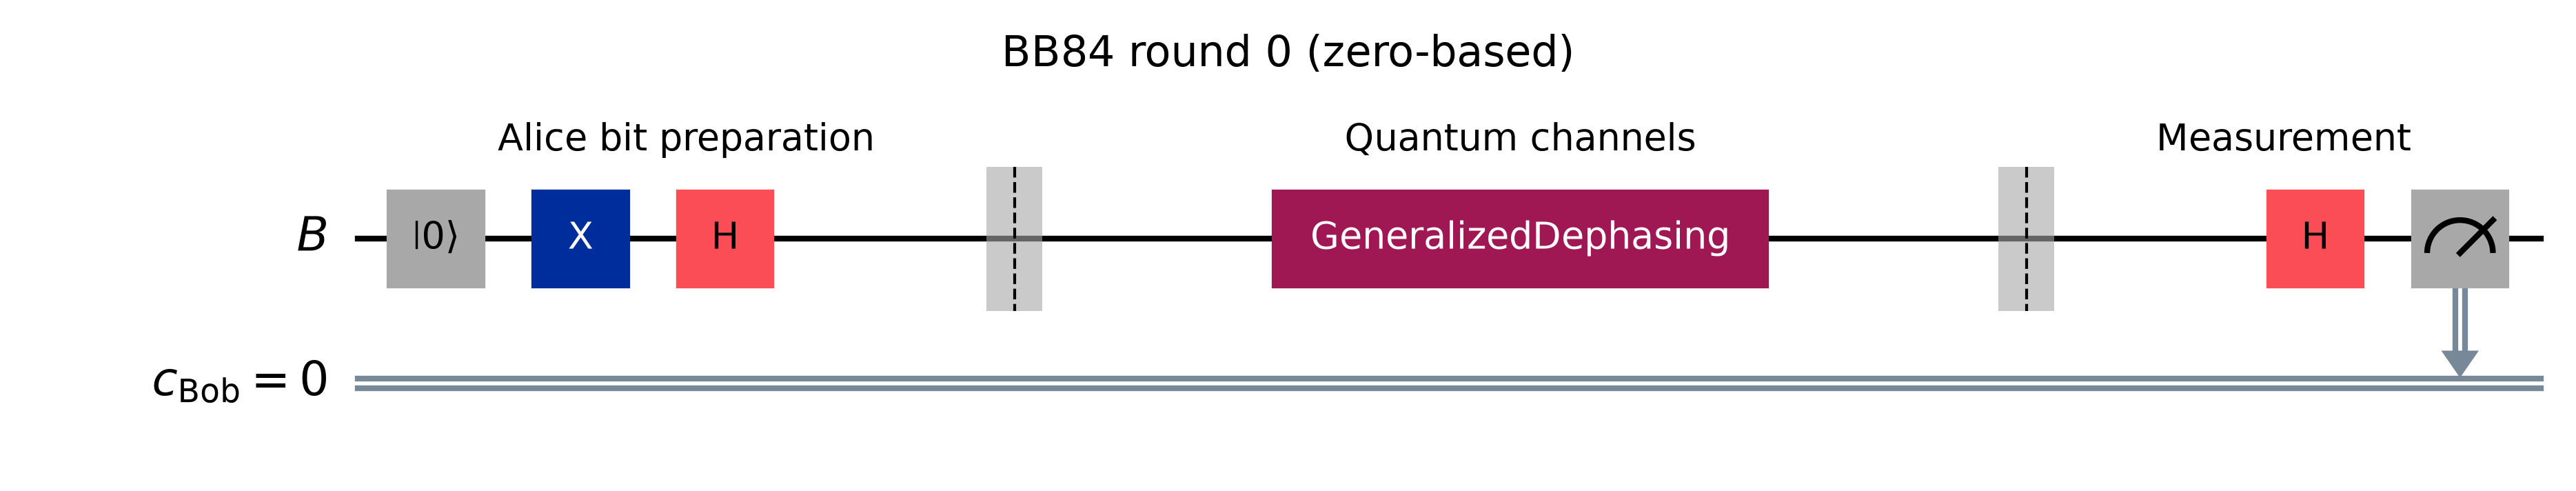

In [18]:
demo_bb = BB84(seed=82, number_bits=24)
demo_bb.key_generation(
    signal_channel=GeneralizedDephasing.from_correlation_matrix([[1, 0.6], [0.6, 1]]),
    record_rounds=range(24),
)
idx = int(np.flatnonzero(demo_bb.sifted_mask)[0])
fig = demo_bb.display(round_index=idx, show=False)
display(fig)


## QubitErasure

Loss is different from replacing a bit by a random value: the receiver knows that the signal was absent. The output Hilbert space must therefore contain a state orthogonal to both computational states. This is why each Kraus matrix has three rows and two columns. The parameter satisfies $0\leq\epsilon\leq1$. Reapplying a qubit channel to a flagged output acts only on the surviving qubit block; the register adds a separate branch that preserves the erasure level. No lost photon is restored by a later gate.

### Mathematical construction

Let $V=|0_3\rangle\langle0_2|+|1_3\rangle\langle1_2|$. The rectangular operators are
$$K_0=\sqrt{1-\epsilon}V,\quad K_1=\sqrt\epsilon|e\rangle\langle0|,\quad K_2=\sqrt\epsilon|e\rangle\langle1|.$$
They obey $\sum K_i^\dagger K_i=I_2$ even though outputs are three dimensional. The linear map is
$$\mathcal N(\rho)=(1-\epsilon)V\rho V^\dagger+\epsilon\operatorname{Tr}(\rho)|e\rangle\langle e|.$$
Measurement uses embedded bit projectors and $P_e=|e\rangle\langle e|$. Outcome 2 means loss. With this channel alone, loss is $\epsilon$ and survivor QBER is zero; at $\epsilon=1$ no sifted key exists and QBER is NaN.

### Parameters and methods
`__init__` constructs the channel from the parameters below; `kraus_operators` gives exactly the matrices derived above. The next demonstration explicitly calls both, followed by inherited `apply` and `apply_each`. Erasure classes additionally demonstrate `measurement_projectors`; generalized dephasing demonstrates both its ordinary constructor and `from_correlation_matrix`.

In [19]:
channel = QubitErasure(0.2)
Ks = channel.kraus_operators()
for k, K in enumerate(Ks):
    print("K", k, K.full())
complete = sum((K.dag() * K for K in Ks), 0 * qeye(Ks[0].dims[1]))
assert (complete - qeye(Ks[0].dims[1])).norm() < 1e-09
r = fresh()
channel.apply(r, "B")
print("output dimensions / state:", r.dims, r.state.full())
r2 = fresh()
r2.add_ancilla("E", basis(2, 1))
channel.apply_each(r2, ["B", "E"])
print("independent outputs:", r2.dims)
bb = BB84(seed=123, number_bits=N)
bb.key_generation(signal_channel=channel)
print("QBER, loss:", bb.qber(), bb.loss_rate())


K 0 [[0.89442719+0.j 0.        +0.j]
 [0.        +0.j 0.89442719+0.j]
 [0.        +0.j 0.        +0.j]]
K 1 [[0.       +0.j 0.       +0.j]
 [0.       +0.j 0.       +0.j]
 [0.4472136+0.j 0.       +0.j]]
K 2 [[0.       +0.j 0.       +0.j]
 [0.       +0.j 0.       +0.j]
 [0.       +0.j 0.4472136+0.j]]
output dimensions / state: [3] [[0.4+0.j 0.4+0.j 0. +0.j]
 [0.4+0.j 0.4+0.j 0. +0.j]
 [0. +0.j 0. +0.j 0.2+0.j]]
independent outputs: [3, 3]
QBER, loss: 0.0 0.17


### Explicit erasure measurement projectors
`measurement_projectors` returns bit-0, bit-1 and erasure projectors in that order. `QuantumRegister.measure` samples and collapses the state.

In [20]:
for b in ("Z", "X"):
    Ps = channel.measurement_projectors(b)
    print(b, [P.full() for P in Ps])
r = fresh()
channel.apply(r, "B")
print(
    "outcome:",
    r.measure("B", channel.measurement_projectors("X"), np.random.default_rng(7)),
)


Z [array([[1.+0.j, 0.+0.j, 0.+0.j],
       [0.+0.j, 0.+0.j, 0.+0.j],
       [0.+0.j, 0.+0.j, 0.+0.j]]), array([[0.+0.j, 0.+0.j, 0.+0.j],
       [0.+0.j, 1.+0.j, 0.+0.j],
       [0.+0.j, 0.+0.j, 0.+0.j]]), array([[0.+0.j, 0.+0.j, 0.+0.j],
       [0.+0.j, 0.+0.j, 0.+0.j],
       [0.+0.j, 0.+0.j, 1.+0.j]])]
X [array([[0.5+0.j, 0.5+0.j, 0. +0.j],
       [0.5+0.j, 0.5+0.j, 0. +0.j],
       [0. +0.j, 0. +0.j, 0. +0.j]]), array([[ 0.5+0.j, -0.5-0.j,  0. +0.j],
       [-0.5+0.j,  0.5+0.j,  0. +0.j],
       [ 0. +0.j,  0. -0.j,  0. +0.j]]), array([[0.+0.j, 0.+0.j, 0.+0.j],
       [0.+0.j, 0.+0.j, 0.+0.j],
       [0.+0.j, 0.+0.j, 1.+0.j]])]
outcome: 0


### BB84 circuit

The diagram below is a recorded, detected round with matching bases. The signal wire is labelled B; probe wires appear when present. Eve’s delayed measurement is included for probe attacks. Noise boxes denote the full channel map; their internal Kraus branches are not individual unitary gates.

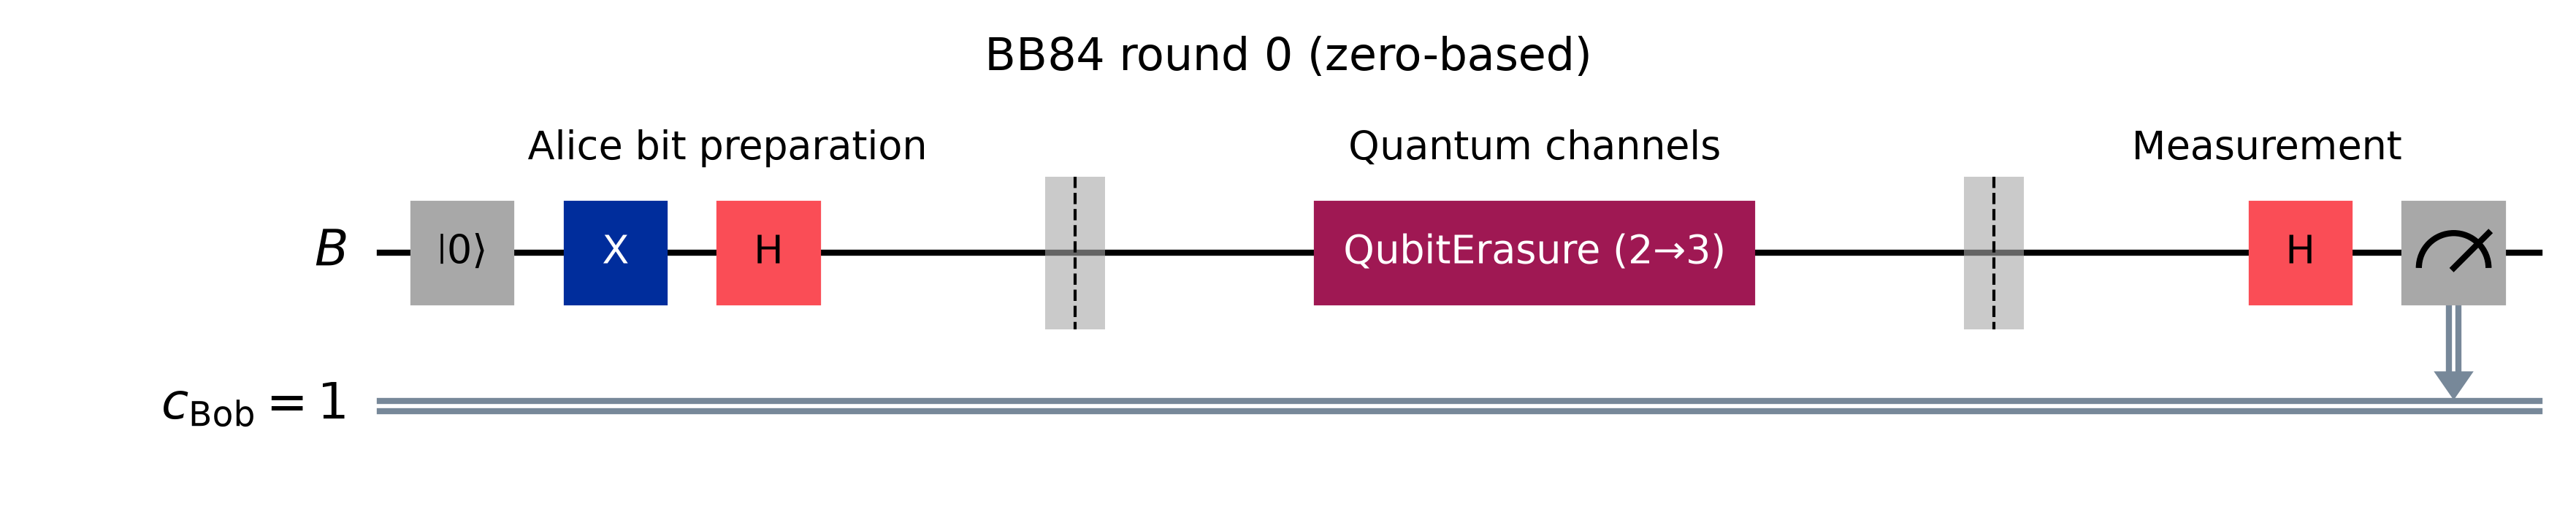

In [21]:
demo_bb = BB84(seed=82, number_bits=24)
demo_bb.key_generation(signal_channel=QubitErasure(0.2), record_rounds=range(24))
idx = int(np.flatnonzero(demo_bb.sifted_mask)[0])
fig = demo_bb.display(round_index=idx, show=False)
display(fig)


## Dephrasure

The two parameters independently control phase disturbance and flagged loss, with $0\leq p,q\leq1$. Setting the loss probability to zero leaves a qubit embedded in a three-dimensional space, while setting the phase probability to zero gives pure erasure. Its `measurement_projectors` method uses exactly the same bit and erasure projectors as `QubitErasure`. The expected sifted key length is approximately $n(1-q)/2$ for a batch of $n$ independent BB84 signals; the realized count fluctuates.

### Mathematical construction

$$K_0=\sqrt{(1-q)(1-p)}V,\quad K_1=\sqrt{(1-q)p}VZ,$$
$$K_2=\sqrt q|e\rangle\langle0|,\quad K_3=\sqrt q|e\rangle\langle1|.$$
Thus
$$\mathcal N(\rho)=(1-q)V[(1-p)\rho+pZ\rho Z]V^\dagger+q\operatorname{Tr}(\rho)|e\rangle\langle e|.$$
The loss flag is orthogonal to both bit states. Conditioning on survival removes the factor $1-q$, leaving phase-flip noise: $Q=p/2$ for uniformly sifted BB84 bases, provided $q<1$.

### Parameters and methods
`__init__` constructs the channel from the parameters below; `kraus_operators` gives exactly the matrices derived above. The next demonstration explicitly calls both, followed by inherited `apply` and `apply_each`. Erasure classes additionally demonstrate `measurement_projectors`; generalized dephasing demonstrates both its ordinary constructor and `from_correlation_matrix`.

In [22]:
channel = Dephrasure(p=0.1, q=0.2)
Ks = channel.kraus_operators()
for k, K in enumerate(Ks):
    print("K", k, K.full())
complete = sum((K.dag() * K for K in Ks), 0 * qeye(Ks[0].dims[1]))
assert (complete - qeye(Ks[0].dims[1])).norm() < 1e-09
r = fresh()
channel.apply(r, "B")
print("output dimensions / state:", r.dims, r.state.full())
r2 = fresh()
r2.add_ancilla("E", basis(2, 1))
channel.apply_each(r2, ["B", "E"])
print("independent outputs:", r2.dims)
bb = BB84(seed=123, number_bits=N)
bb.key_generation(signal_channel=channel)
print("QBER, loss:", bb.qber(), bb.loss_rate())


K 0 [[0.84852814+0.j 0.        +0.j]
 [0.        +0.j 0.84852814+0.j]
 [0.        +0.j 0.        +0.j]]
K 1 [[ 0.28284271+0.j  0.        +0.j]
 [ 0.        +0.j -0.28284271+0.j]
 [ 0.        +0.j  0.        +0.j]]
K 2 [[0.       +0.j 0.       +0.j]
 [0.       +0.j 0.       +0.j]
 [0.4472136+0.j 0.       +0.j]]
K 3 [[0.       +0.j 0.       +0.j]
 [0.       +0.j 0.       +0.j]
 [0.       +0.j 0.4472136+0.j]]
output dimensions / state: [3] [[0.4 +0.j 0.32+0.j 0.  +0.j]
 [0.32+0.j 0.4 +0.j 0.  +0.j]
 [0.  +0.j 0.  +0.j 0.2 +0.j]]
independent outputs: [3, 3]
QBER, loss: 0.05232558139534884 0.17


### Explicit erasure measurement projectors
`measurement_projectors` returns bit-0, bit-1 and erasure projectors in that order. `QuantumRegister.measure` samples and collapses the state.

In [23]:
for b in ("Z", "X"):
    Ps = channel.measurement_projectors(b)
    print(b, [P.full() for P in Ps])
r = fresh()
channel.apply(r, "B")
print(
    "outcome:",
    r.measure("B", channel.measurement_projectors("X"), np.random.default_rng(7)),
)


Z [array([[1.+0.j, 0.+0.j, 0.+0.j],
       [0.+0.j, 0.+0.j, 0.+0.j],
       [0.+0.j, 0.+0.j, 0.+0.j]]), array([[0.+0.j, 0.+0.j, 0.+0.j],
       [0.+0.j, 1.+0.j, 0.+0.j],
       [0.+0.j, 0.+0.j, 0.+0.j]]), array([[0.+0.j, 0.+0.j, 0.+0.j],
       [0.+0.j, 0.+0.j, 0.+0.j],
       [0.+0.j, 0.+0.j, 1.+0.j]])]
X [array([[0.5+0.j, 0.5+0.j, 0. +0.j],
       [0.5+0.j, 0.5+0.j, 0. +0.j],
       [0. +0.j, 0. +0.j, 0. +0.j]]), array([[ 0.5+0.j, -0.5-0.j,  0. +0.j],
       [-0.5+0.j,  0.5+0.j,  0. +0.j],
       [ 0. +0.j,  0. -0.j,  0. +0.j]]), array([[0.+0.j, 0.+0.j, 0.+0.j],
       [0.+0.j, 0.+0.j, 0.+0.j],
       [0.+0.j, 0.+0.j, 1.+0.j]])]
outcome: 0


### BB84 circuit

The diagram below is a recorded, detected round with matching bases. The signal wire is labelled B; probe wires appear when present. Eve’s delayed measurement is included for probe attacks. Noise boxes denote the full channel map; their internal Kraus branches are not individual unitary gates.

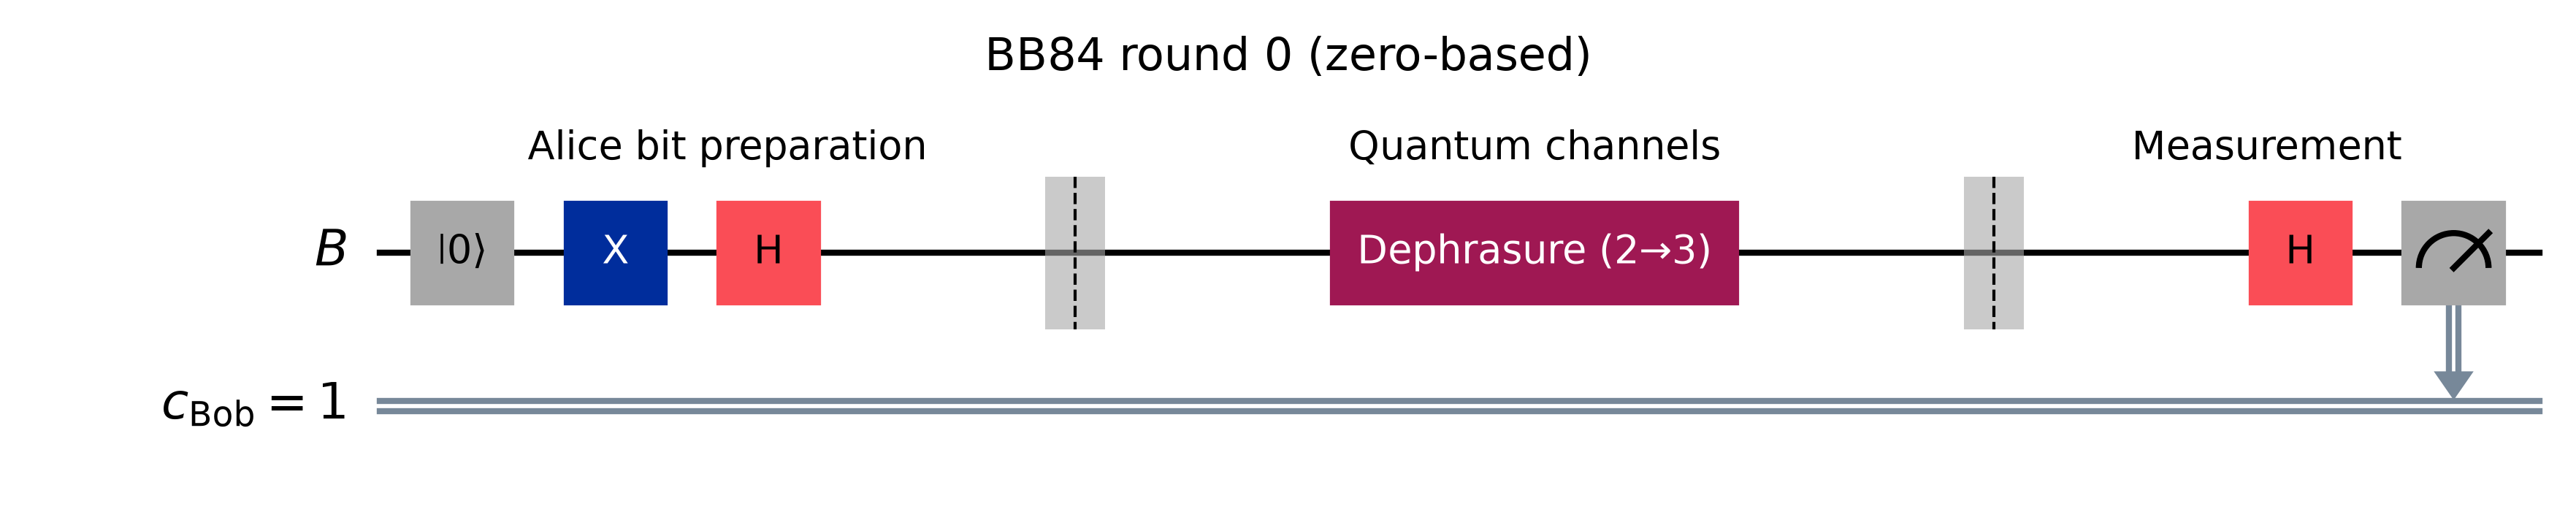

In [24]:
demo_bb = BB84(seed=82, number_bits=24)
demo_bb.key_generation(signal_channel=Dephrasure(p=0.1, q=0.2), record_rounds=range(24))
idx = int(np.flatnonzero(demo_bb.sifted_mask)[0])
fig = demo_bb.display(round_index=idx, show=False)
display(fig)


## Base class and probe-specific noise
`QuantumChannel` is abstract: subclasses supply `kraus_operators`. Its `apply` passes Kraus operators and erasure metadata to the register; `apply_each` repeats a one-target channel independently. `ProbeNoise` is a utility rather than a new joint channel: its constructor validates a nonempty mapping, `num_targets` counts probes, and `apply`/`apply_each` require the exact configured probe labels.

In [25]:
noise = ProbeNoise({"E": AmplitudeDamping(0.2), "F": QubitErasure(0.1)})
print("probe count:", noise.num_targets)
for method in (noise.apply, noise.apply_each):
    r = fresh()
    FGGNPAttack(seed=9).apply(r)
    method(r, ["E", "F"])
    print(r.dims)
bb = BB84(seed=10, number_bits=N)
bb.key_generation(FGGNPAttack(seed=11), memory_channel=noise)
print(bb.eve_optimal_success())


probe count: 2
[2, 2, 3]
[2, 2, 3]
{'Z': 0.7400000000000001, 'X': 0.7453288405385718}


## Channel placement and interpretation
`alice_eve_channel` acts before Eve; `signal_channel` acts after Eve; `memory_channel` acts only on retained probes. Their placement can change Eve’s information even when Bob’s error rate looks similar. Loss and QBER use different denominators: loss counts all transmissions, QBER only detected matching-basis rounds. These simulations do not produce a security-certified final key.

In [26]:
bb = BB84(seed=20, number_bits=N)
bb.key_generation(
    CNOTAttack(seed=21),
    alice_eve_channel=QubitErasure(0.1),
    signal_channel=PhaseFlip(0.05),
    memory_channel=AmplitudeDamping(0.2),
)
print(bb.qber(), bb.loss_rate(), bb.eve_optimal_success())


0.22674418604651161 0.105 {'Z': 0.9000000000000001, 'X': 0.5}
